In [1]:
%load_ext autoreload
%autoreload 2

# Visualize the basic characteristics of select LME locations
Open questions about which regions to focus on. For the purpose of progress, I'll focus on the upwelling eastern boundaries here.
- [x] global map with LMEs highlighted
- [x] regional maps of primary production (and comparison to observations)
- [x] regional maps of SST
- [ ] fraction of global primary production occuring in each LME

In [2]:
import esm4ppe
from functions import *
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs

In [3]:
# open static
static = esm4ppe.open_static('intpp','monthly')

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [4]:
# open masks
LME_subset = ['California Current','Gulf of California',
              'Pacific Central-American Coastal','Humboldt Current',
              'Canary Current','Guinea Current','Benguela Current']
masks = esm4ppe.masks.get_masks('LME',static)

In [5]:
# open climatology
ds = esm4ppe.open_climatology('ocean','monthly')
ds

<xarray.Dataset>
Dimensions:    (xh: 720, yh: 576, month: 12)
Coordinates:
  * xh         (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh         (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
  * month      (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    MLD_003    (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>
    intpp      (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>
    intppdiat  (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>
    intppdiaz  (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>
    intppmisc  (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>
    intpppico  (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>
    tos        (month, yh, xh) float32 dask.array<chunksize=(12, 576, 720), meta=np.ndarray>

In [6]:
variable_kwargs = {'tos':{'vmin':-2,'vmax':30},'intpp':{'vmin':0,'vmax':2e-6}}

### Fraction of global NPP in LMEs

In [16]:
import pandas as pd
# derive seconds per month for standard non-leap year
months = pd.date_range('2009-12-31','2010-12-31',freq='1M')
spm = xr.DataArray(months.diff().total_seconds()[1:],coords={'month':ds['month']})
# integrate through year
da = ds['intpp'].weighted(spm).sum('month')
# global intpp
intpp_global = da.weighted(static['areacello']).sum(['xh','yh'])

In [23]:
# area integrals
intpp_ai = xr.Dataset()
area_ai = xr.Dataset()
for region,mask in masks.items():
    intpp_ai[region] = (da*mask).weighted(static['areacello']).sum(['xh','yh'])
    area_ai[region] = (mask).weighted(static['areacello']).sum(['xh','yh'])
intpp_ai = intpp_ai.to_array(dim='region')
area_ai = area_ai.to_array(dim='region')

In [26]:
# area mean
intpp_am = (intpp_ai/area_ai)
# sort based on area mean
LMEs_sorted = intpp_am['region'].sortby(intpp_am)

(0.0, 25.0)

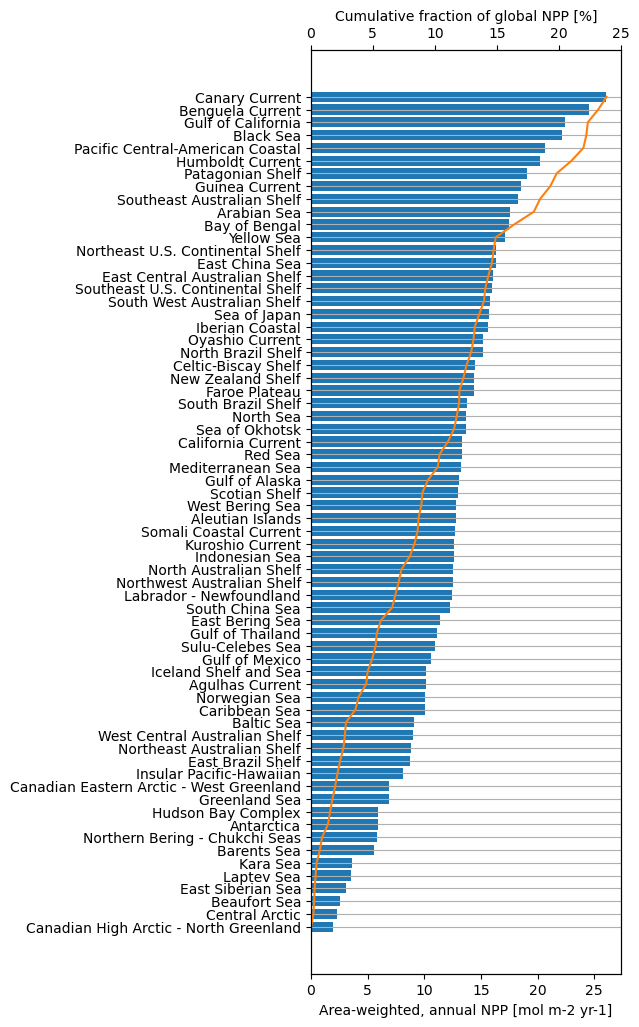

In [38]:
intpp_am_sorted = intpp_am.sel(region=LMEs_sorted)
intpp_ai_sorted = intpp_ai.sel(region=LMEs_sorted)

fig,ax = plt.subplots(figsize=(4,12))
ax.barh(intpp_am_sorted.region,intpp_am_sorted)
ax.grid(axis='y')
ax.set_xlabel('Area-weighted, annual NPP [mol m-2 yr-1]')
ax.set_xlim([0,30])
ax2 = ax.twiny()
ax2.plot(((intpp_ai_sorted/intpp_global)*100).cumsum(),intpp_ai_sorted.region,color='tab:orange')
ax2.set_xlabel('Cumulative fraction of global NPP [%]')
ax2.set_xlim([0,25])

## Global map of primary production with LMEs overlaid

In [19]:
variable = 'intpp'
X = static["geolon"]
Y = static["geolat"]
Z = ds[variable].max("month")

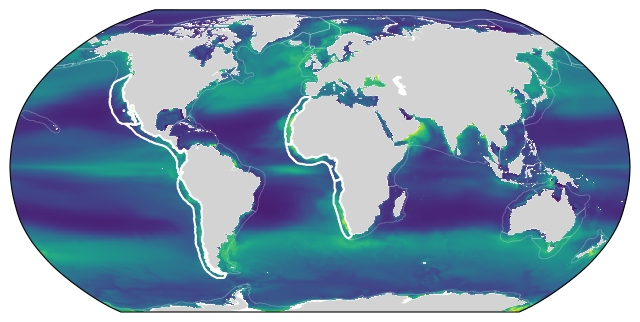

In [8]:
kw_args = variable_kwargs[variable]
fig,ax = plt.subplots(figsize=(8,4),subplot_kw={'projection':ccrs.Robinson(central_longitude=0)})
ax.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree(),**kw_args)
ax.add_feature(cartopy.feature.LAND,facecolor='lightgrey')
for region,da in masks.items():
    if region in LME_subset:
        color = 'white'
        alpha=1
        linewidth=1.5
    else:
        color = 'white'
        alpha=0.3
        linewidth=0.5
    ax.contour(X,Y,da.transpose(),levels=[0.5],colors=color,linewidths=linewidth,transform=ccrs.PlateCarree(),alpha=alpha)

## Regional maps

In [9]:
import matplotlib.path as mpath
import numpy as np

def get_boundaries(region, masks, static, buffer=3):
    # need to do the subsetting slightly carefully
    # we want the drop functionality, but we don't want to set the values outside the condition to NaN
    # so first use .where to drop, then select static for the region based on this subset
    static_subset = static.where(masks[region]==1,drop=True)
    static_region = static.sel({"xh":static_subset["xh"],"yh":static_subset["yh"]})
    # get boundaries of region
    lons,lats = (
        [static_region["geolon"].min().values-buffer,
         static_region["geolon"].max().values+buffer],
        [static_region["geolat"].min().values-buffer,
         static_region["geolat"].max().values+buffer]
    )
    return lons, lats

In [10]:
def draw_regionalmap(ax,da,static,region,masks,buffer=3,**kw_args):
    X = static["geolon"]
    Y = static["geolat"]
    Z = da
    lons,lats = get_boundaries(region, masks=masks, static=static, buffer=buffer)
    im = ax.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree(),**kw_args)
    ax.contour(X,Y,masks[region].transpose(),levels=[0.5],colors='white',linewidths=0.5,transform=ccrs.PlateCarree(),alpha=0.5)
    ax.set_extent((lons[0],lons[1],lats[0],lats[1]))
    ax.add_feature(cartopy.feature.LAND, zorder=1, edgecolor='k')
    ax.gridlines(
        draw_labels=True, rotate_labels=False,
        x_inline=False, y_inline=False,
    )
    ax.set_title(region)
    return im,ax

In [11]:
variable = 'tos'
da = ds[variable].mean("month")

kw_args = variable_kwargs[variable]

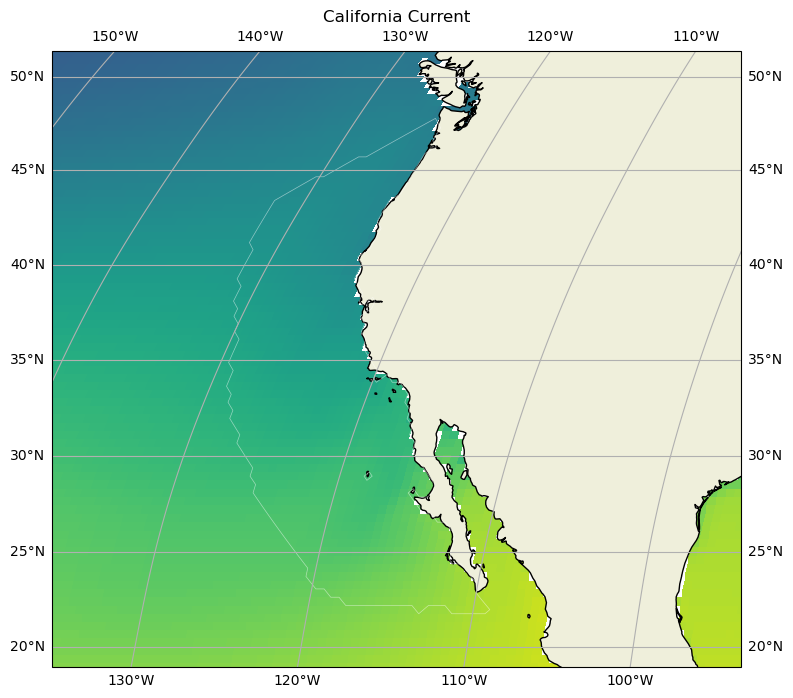

In [12]:
region = LME_subset[0]
proj = ccrs.Robinson()
fig, ax = plt.subplots(figsize=(12, 8),
                       subplot_kw={'projection':proj})
im, ax = draw_regionalmap(ax,da,static,region,masks,**kw_args)